# 06 · Visual comparison of the ponds

**Goal:** compare water quality and fish growth across ponds after cleaning.

Each variable gets its own panel with its own unit, because temperature (°C), oxygen and nitrate (mg/L), pH and weight (g) cannot share one axis. Statistics are computed on the cleaned data from notebook 03, so sensor error codes (−127 °C, ammonia of 4.27e11 or `inf`) no longer distort the means.

**Input:** `data/processed/pond_clean.csv`, `data/processed/pond_day.csv` · **Output:** figures in `results/figures/`

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import importlib
import src.pond_pipeline
importlib.reload(src.pond_pipeline)  # pick up edits to src/ even if this kernel imported it earlier
from src.pond_pipeline import *  # noqa: F401,F403  (column names, thresholds, helpers)

# Raw pond CSVs live in data/raw/ (see data/README.md). Override with POND_RAW_DIR if needed.
RAW = Path(os.environ.get("POND_RAW_DIR", RAW_DIR))
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.dpi": 110})
MARK = "#2a6fb0"  # one hue: ponds are compared by position, not by colour

clean = pd.read_csv(PROCESSED_DIR / "pond_clean.csv", parse_dates=["timestamp"])
pond_day = pd.read_csv(PROCESSED_DIR / "pond_day.csv", parse_dates=["date"])
ponds = sorted(clean["pond_id"].unique())
print(len(clean), "readings,", len(ponds), "ponds")

1114261 readings, 11 ponds


### Which processed data is used

Shows the file this notebook reads, when notebook 03 wrote it, and which version of the cleaning made it. If it warns, restart notebook 03's kernel and run it again.

In [3]:
check_processed(PROCESSED_DIR / "pond_day.csv")

file:     C:\Users\99451\OneDrivee\Desktop\pond_dataset\data\processed\pond_day.csv
written:  2026-11-25 14:04:38
made by:  2026-11-25.4 (dates per column, stale weights, pond 11 restock, DO 0.01-20)
src code: 2026-11-25.4 (dates per column, stale weights, pond 11 restock, DO 0.01-20)  (C:\Users\99451\OneDrivee\Desktop\pond_dataset\src\pond_pipeline.py)


,rows,first,last,max_weight
pond_id,,,,
1,81,2021-06-19,2021-10-13,318.640000
2,111,2021-06-19,2021-10-31,394.660000
3,76,2021-06-19,2021-10-12,294.920000
4,68,2021-06-19,2021-09-05,223.730000
6,89,2021-06-19,2021-10-13,304.760000
7,127,2021-06-18,2021-12-30,1026.457143
8,56,2021-06-18,2021-12-06,841.200000
9,101,2021-06-18,2021-10-13,431.200000
10,18,2021-06-25,2021-12-05,689.142900


## Water quality per pond: median and interquartile range

The dot is the median; the bar spans the 25th to 75th percentile. Medians are used instead of means because the sensor readings are skewed.

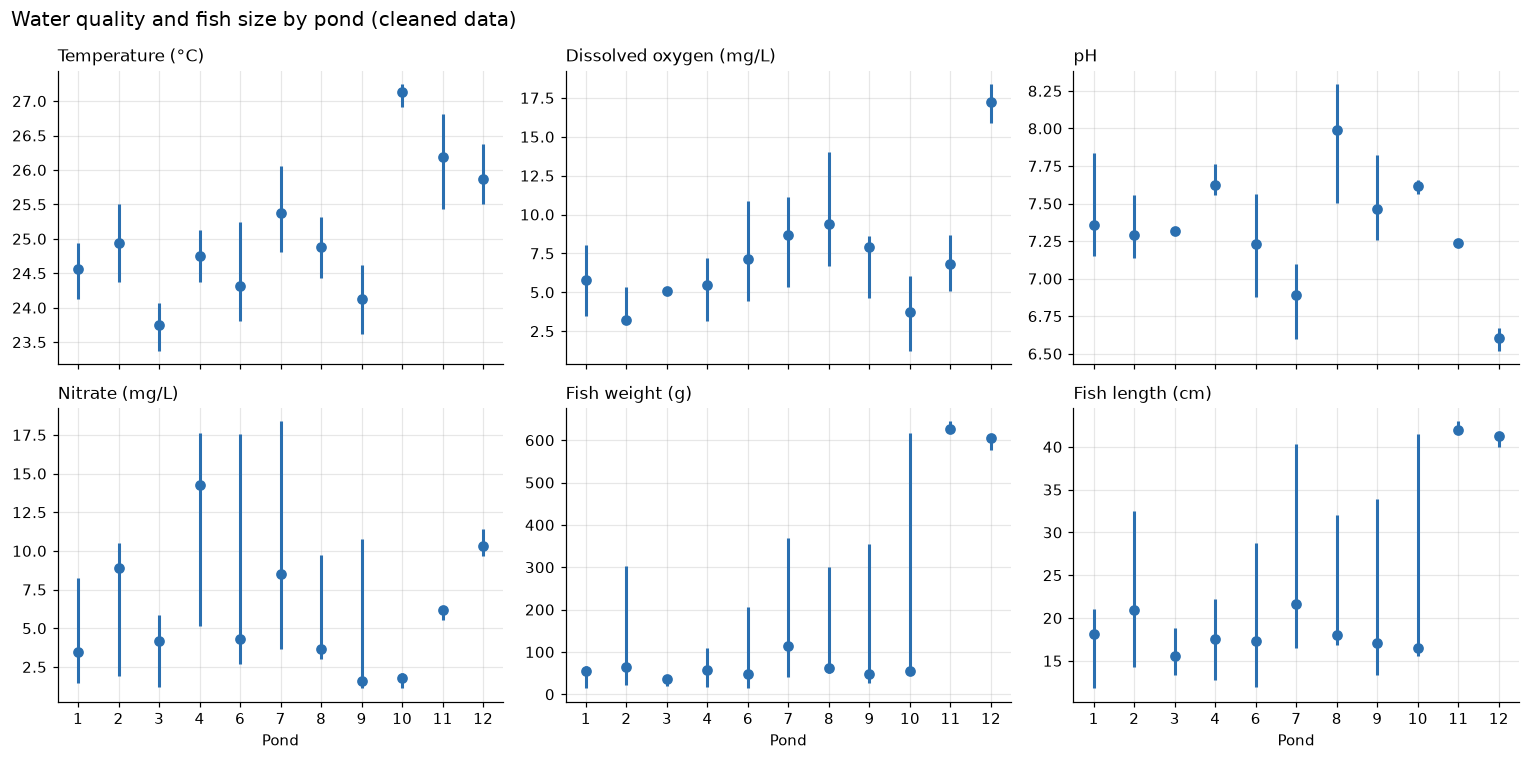

In [4]:
VARS = {TEMP: "Temperature (°C)", DO: "Dissolved oxygen (mg/L)", PH: "pH", NITRATE: "Nitrate (mg/L)",
        WEIGHT: "Fish weight (g)", LENGTH: "Fish length (cm)"}
q = clean.groupby("pond_id")[list(VARS)].quantile([0.25, 0.5, 0.75]).unstack()

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
x = range(len(ponds))
for ax, (col, label) in zip(axes.flat, VARS.items()):
    med, lo, hi = q[(col, 0.5)], q[(col, 0.25)], q[(col, 0.75)]
    ax.errorbar(x, med, yerr=[med - lo, hi - med], fmt="o", color=MARK, ms=6, capsize=0, lw=2)
    ax.set_title(label, loc="left", fontsize=11)
    ax.set_xticks(list(x), [str(p) for p in ponds])
for ax in axes[-1]:
    ax.set_xlabel("Pond")
fig.suptitle("Water quality and fish size by pond (cleaned data)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "pond_comparison.png", bbox_inches="tight")
plt.show()

The same statistics as a table, for exact values:

In [5]:
summary = clean.groupby("pond_id")[list(VARS)].agg(["median", "mean", "min", "max"]).round(2)
summary.to_csv(RESULTS_DIR / "statistics_after_cleaning_by_pond.csv")
summary

Temperature (C)                      Dissolved Oxygen(mg/L)         \
                 median   mean    min    max                 median   mean   
pond_id                                                                      
1                 24.56  24.54  23.00  26.12                   5.82   6.21   
2                 24.94  24.97  23.00  27.19                   3.20   4.38   
3                 23.75  23.75  22.31  25.25                   5.08   5.19   
4                 24.75  24.74  23.25  26.25                   5.47   5.51   
6                 24.31  24.51  22.56  27.38                   7.13   7.86   
7                 25.38  25.49  22.88  28.06                   8.69   8.87   
8                 24.88  24.91  23.12  26.75                   9.39  10.01   
9                 24.12  24.16  22.12  26.25                   7.92   7.23   
10                27.12  27.10  25.75  28.25                   3.73   4.15   
11                26.19  26.08  24.25  27.38                   6.79   7.08   
12                25.88  25.93  24.69  27.12                  17.22  17.03   

                          PH        ... Nitrate(mg/L)        Fish_Weight(g)  \
           min    max median  mean  ...           min    max         median   
pond_id                             ...                                       
1         0.02  18.33   7.36  7.54  ...          0.45  16.63          54.70   
2         0.02  12.05   7.29  7.41  ...          0.45  22.24          65.48   
3         2.37   9.22   7.32  7.32  ...          0.00  12.77          35.83   
4         0.02  15.02   7.63  7.68  ...          2.15  24.93          58.48   
6         0.01  20.00   7.23  7.24  ...          0.89  25.00          47.85   
7         0.01  20.00   6.89  6.87  ...          0.00  25.00         114.13   
8         0.02  20.00   7.99  7.95  ...          0.00  19.83          61.11   
9         0.02  17.25   7.47  7.51  ...          0.00  22.69          49.00   
10        0.01  15.02   7.62  7.61  ...          0.00   3.35          54.06   
11        0.02  17.74   7.24  7.24  ...          4.59   7.71         625.89   
12       11.06  19.99   6.61  6.62  ...          8.32  14.46         605.36   

                                Fish_Length(cm)                       
           mean    min      max          median   mean    min    max  
pond_id                                                               
1         44.57   2.91   318.64           18.08  16.41   7.11  33.45  
2        166.49   3.36   394.66           20.97  23.43   6.96  35.39  
3         44.26   3.20   294.92           15.54  16.06   6.74  33.00  
4         70.37   3.07   223.73           17.60  17.49   6.94  29.07  
6         88.95   3.20   304.76           17.36  18.60   7.30  32.37  
7        279.85   3.04  1026.46           21.70  30.61   6.77  69.99  
8        144.07   2.87   841.20           18.04  21.97   6.82  51.36  
9        171.76   4.37   431.20           17.05  22.47   6.95  36.15  
10       261.47  27.60   689.14           16.51  26.27  13.45  44.55  
11       515.93  33.80   701.00           41.96  36.89  14.12  44.65  
12       550.53  28.60   620.93           41.27  39.53  14.64  41.66  

[11 rows x 24 columns]

## Fish growth per pond

Daily fish weight against days since the pond's first record, one small panel per pond on a shared scale.

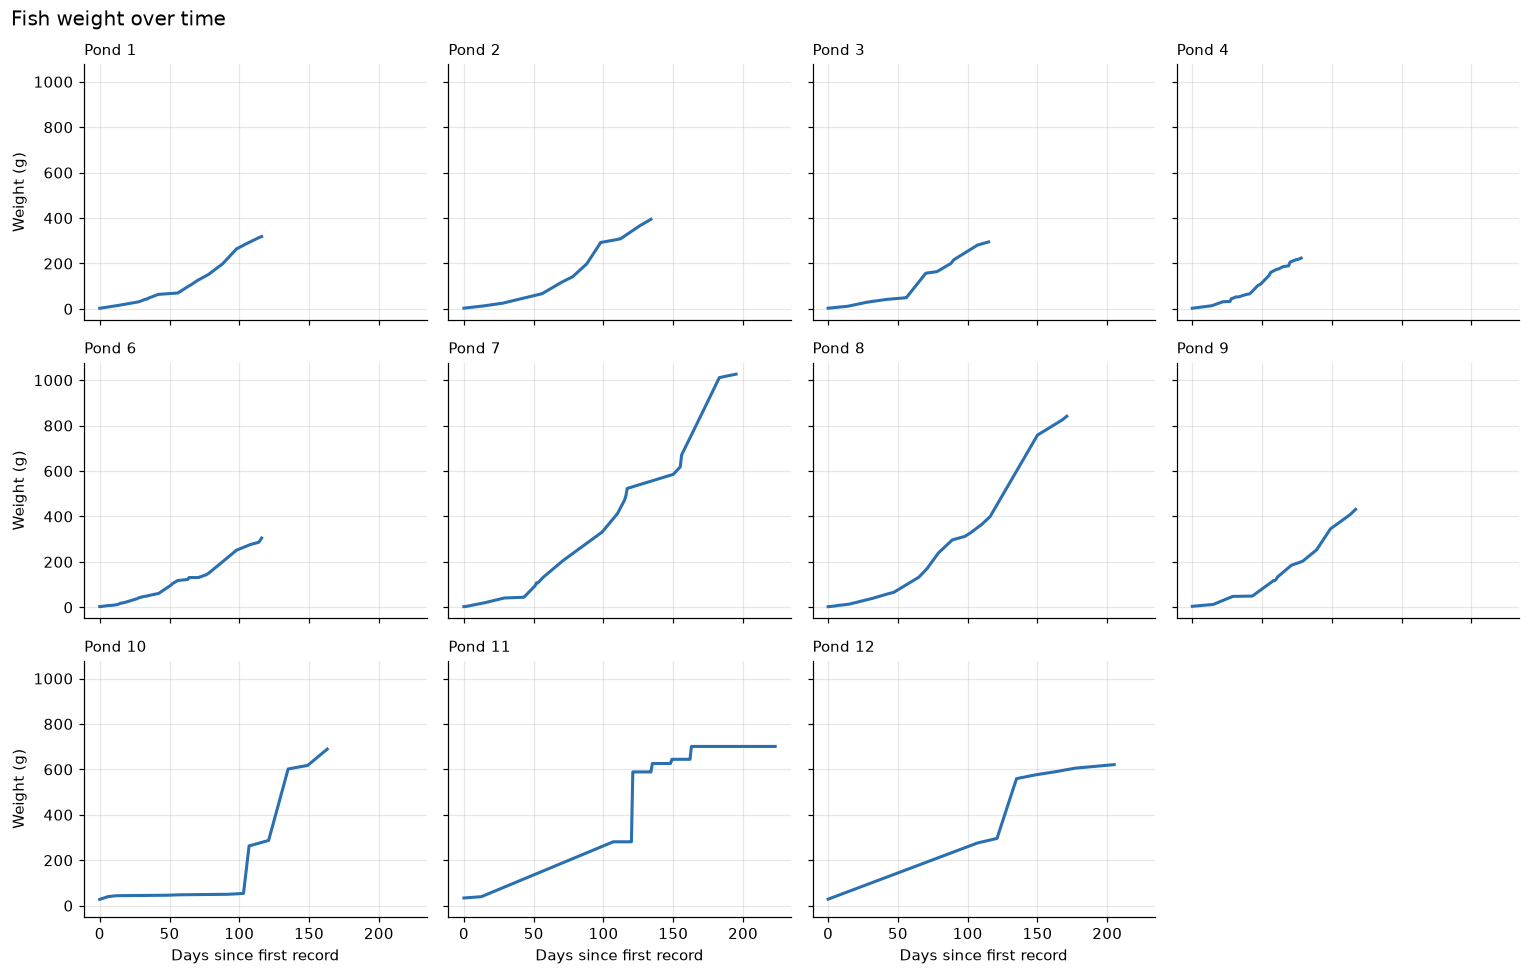

In [6]:
n = len(ponds)
cols = 4
rows = -(-n // cols)
fig, axes = plt.subplots(rows, cols, figsize=(14, 3 * rows), sharex=True, sharey=True)
for ax, pond in zip(axes.flat, ponds):
    d = pond_day[pond_day["pond_id"] == pond]
    ax.plot(d["days_since_start"], d[WEIGHT], color=MARK, lw=2)
    ax.set_title(f"Pond {pond}", loc="left", fontsize=10)
for ax in axes.flat[n:]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("Weight (g)")
for ax in axes[-1]:
    ax.set_xlabel("Days since first record")
fig.suptitle("Fish weight over time", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "growth_by_pond.png", bbox_inches="tight")
plt.show()

## Data quality: share of raw readings outside the reference range

From notebook 01. Darker cells mean more readings outside the range; turbidity and ammonia are dropped for this reason. For dissolved oxygen the cell is the share below the 5 mg/L stress level, which is reported but not removed.

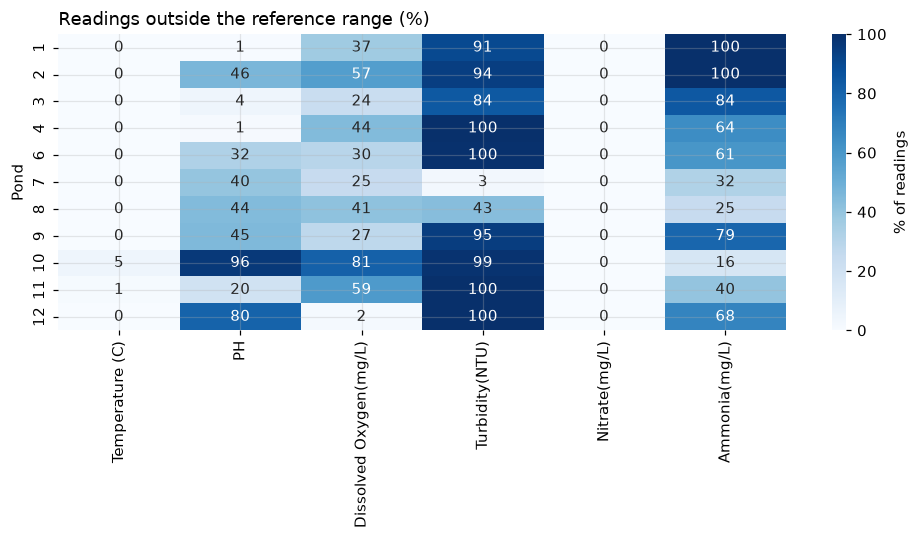

In [7]:
per_pond = wrong_value_summary(load_all_ponds(RAW), by="pond_id")
pct = per_pond[[c for c in per_pond.columns if c.endswith("(%)")]]
pct.columns = [c.replace(" (%)", "") for c in pct.columns]
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pct, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "% of readings"}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Pond")
ax.set_title("Readings outside the reference range (%)", loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "invalid_share_heatmap.png", bbox_inches="tight")
plt.show()